# CXR-Sentry · Section 3: report sampling and uncertainty (V5: official splits)

This notebook continues from the generator handoff (Participant 1) (`iu-baseline-100ep-seed42`, commit `46e3d8c`). It covers:

1. Five sampled reports per study from the generator checkpoint, with temperature, top-p, seed, output length and checkpoint version recorded.
2. One shared **CheXbert** wrapper, used for reference, greedy and sampled reports. It keeps all four states: positive, negative, uncertain and unmentioned.
3. **Finding-state entropy** per finding, aggregated to one score per report.
4. **Bidirectional NLI** checks, deterministic semantic clustering and **semantic entropy** per report.
5. A sampling-sensitivity check on **dev**, a frozen setting, then the **test** split.
6. Handoff files for Person 2 (labels) and Person 4 (labels and uncertainty scores).

**Before you start, put these in Google Drive** (the paths can be changed in Step 3):

```
MyDrive/CXR-Sentry/handoff/
├── iu-baseline-100ep-seed42.zip   ← the generator handoff zip (checkpoint, its own train/dev manifest, greedy drafts)
└── splits/                        ← the official split CSVs (Participant 2's handoff) from "Participant 3.zip":
                                     train.csv, dev.csv, prob_cal.csv, risk_cal.csv, test.csv
```

**Images:** put the IU PNG images in `MyDrive/CXR-Sentry/handoff/images/`, as one zip, several zips (Drive splits big downloads) or loose PNGs. The notebook copies only the PNGs the manifest uses to Colab's local disk. If you can see the shared MLH folder from this account instead, set `IMAGES_SRC = Path("/content/drive/MyDrive/MLH/dataset/NLMCXR_png")` in Step 3.

**Runtime:** Runtime → Change runtime type → **GPU** (A100 or L4 is fastest; T4 also works).

Every output is saved under `MyDrive/CXR-Sentry/person3_outputs/`. Sampling is **resumable**: if Colab disconnects, rerun Steps 1–7 and sampling picks up where it stopped.

## Step 1: Check the GPU

In [1]:
!nvidia-smi

Sat Nov 28 04:58:28 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   35C    P8             12W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Step 2: Install the same library versions the generator was trained with
These versions match the generator's `environment.txt`. Colab's own `torch` is kept.
If the cell prints a ⚠️ line or pip asks you to restart, use **Runtime → Restart session**, then continue from Step 3. Don't rerun this cell. (`torchao` is upgraded too, because PEFT's version check needs it on Colab.)

In [2]:
!pip install -q transformers==5.23.0 peft==0.21.3 huggingface_hub==2.4.0 torchxrayvision==1.5.7 sentencepiece==0.2.3 "torchao>=0.16.0"
import torch, transformers, peft, torchxrayvision
print("torch", torch.__version__, "| transformers", transformers.__version__, "| peft", peft.__version__,
      "| torchxrayvision", torchxrayvision.__version__, "| CUDA:", torch.cuda.is_available())
if transformers.__version__ != "5.23.0":
    print("⚠️ transformers is", transformers.__version__, "not 5.23.0 → Runtime → Restart session, then continue from Step 3.")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.


W1128 04:59:01.988000 483 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1128 04:59:02.029000 483 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


torch 2.14.1+cu130 | transformers 5.23.0 | peft 0.21.3 | torchxrayvision 1.5.7 | CUDA: True


## Step 3: Mount Drive and set the configuration
**Check `FINDINGS` and `AGGREGATION` against the proposal.** The defaults are the five CheXpert competition findings and a mean over findings. Change them here if the proposal says otherwise, before generating any results.

In [3]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import shutil

# ---- Paths: edit if your Drive layout is different ----
DRIVE_ROOT   = Path("/content/drive/MyDrive/CXR-Sentry")
HANDOFF_DIR  = DRIVE_ROOT / "handoff"
HANDOFF_ZIP  = HANDOFF_DIR / "iu-baseline-100ep-seed42.zip"
# Images: a folder of PNGs, a folder of zips (e.g. Drive's split download), or one zip.
IMAGES_SRC   = Path("/content/drive/MyDrive/MLH/dataset/NLMCXR_png")   # your MLH shortcut
SPLITS_DIR   = HANDOFF_DIR / "splits"   # official split CSVs (train/dev/prob_cal/risk_cal/test.csv)
OFFICIAL_MANIFEST = HANDOFF_DIR / "manifest_full.csv"   # NOT used when splits/ has files (it is a different split)
OUT_DIR      = DRIVE_ROOT / "person3_outputs"

LOCAL    = Path("/content/work")          # fast local disk for images
REPO_DIR = Path("/content/CXR-Sentry")

# ---- Generator version (from the handoff's git_commit.txt and checkpoint) ----
GENERATOR_COMMIT = "46e3d8c62ec18e9d3f943da07c80e0d157cb4a28"
CHECKPOINT_ID    = "iu-baseline-100ep-seed42"

# ---- Study settings: confirm with the proposal ----
FINDINGS    = ["Atelectasis", "Cardiomegaly", "Consolidation", "Edema", "Pleural Effusion"]
AGGREGATION = "mean"        # report-level finding-state entropy: "mean", "max" or "sum" over FINDINGS
NUM_SAMPLES = 5
MAX_NEW_TOKENS = 128        # same limit as the greedy exports
BASE_SEED   = 42

# Sampling settings compared on DEV only. Key = tag used in file names.
SAMPLING_GRID = {
    "t0.7_p0.90": (0.7, 0.90),   # generate.py default
    "t1.0_p0.95": (1.0, 0.95),
    "t1.0_p1.00": (1.0, 1.00),
    "t1.3_p1.00": (1.3, 1.00),
}

NLI_MODEL = "MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli"   # proposal ref [5]

# Safety check: leave out of generator-based outputs any study the checkpoint was trained on.
# With the official split CSVs this excludes 0 studies (see generator_overlap.csv).
EXCLUDE_GENERATOR_TRAINING_STUDIES = True
FINAL_SPLITS = ["test", "risk_cal"]   # splits that get samples + uncertainty after freezing (Person 4 needs risk_cal)
BOOTSTRAP_REPS = 1000                 # for the AUROC confidence intervals in Step 12
CHEXBERT_REPO, CHEXBERT_FILE = "StanfordAIMI/RRG_scorers", "chexbert.pth"
DEVICE = "cuda"

for sub in ("samples", "labels", "uncertainty", "greedy", "validation", "nli_cache"):
    (OUT_DIR / sub).mkdir(parents=True, exist_ok=True)
SPLITS_DIR.mkdir(parents=True, exist_ok=True)
assert HANDOFF_ZIP.exists(), f"Upload the generator checkpoint zip to {HANDOFF_ZIP}"
assert IMAGES_SRC.exists(), f"Images not found at {IMAGES_SRC}. Put the image zip(s) there (or fix IMAGES_SRC)"
print("Config OK. Outputs go to", OUT_DIR)

Mounted at /content/drive
Config OK. Outputs go to /content/drive/MyDrive/CXR-Sentry/person3_outputs


## Step 4: Get the generator code at the exact commit that trained the checkpoint

In [4]:
import os, sys, subprocess, shutil

# Clone the whole repo and check out the exact commit, so this works before AND after
# the generator branch is merged into main (it doesn't depend on the branch name).
if not REPO_DIR.exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/Shivank19/CXR-Sentry.git", str(REPO_DIR)], check=True)
subprocess.run(["git", "-C", str(REPO_DIR), "fetch", "-q", "--all"], check=True)
subprocess.run(["git", "-C", str(REPO_DIR), "checkout", "-q", GENERATOR_COMMIT], check=True)
print(subprocess.run(["git", "-C", str(REPO_DIR), "log", "-1", "--oneline"],
                     capture_output=True, text=True).stdout)

src = str(REPO_DIR / "src")
if src not in sys.path:
    sys.path.insert(0, src)
os.environ["PYTHONPATH"] = src

46e3d8c Add prepared dataset manifest conversion



## Step 5: Unpack the checkpoint, build the official manifest, copy images
- Reads the official split CSVs (Participant 2's handoff) from `handoff/splits/` (`study_id, image_id, image_path, target_text, view_label, ...`; the split comes from the file name). These are the splits the generator was trained on, so the overlap table should show **0** generator-trained studies outside train.
- Matches images by study number + `IM-xxxx-xxxx`, so `1_IM-0001-4001.dcm.png` finds `CXR1_1_IM-0001-4001.png` in the IU folder.
- Compares the official split with the studies the checkpoint was **trained on** (from the generator handoff's own manifest) and saves `validation/generator_overlap.csv`.

In [5]:
import zipfile, shutil, csv, json, hashlib, re
import pandas as pd
from tqdm.auto import tqdm

LOCAL.mkdir(parents=True, exist_ok=True)
RUN_DIR = LOCAL / "iu-baseline-100ep-seed42"
if not RUN_DIR.exists():
    with zipfile.ZipFile(HANDOFF_ZIP) as z:
        z.extractall(LOCAL)
CHECKPOINT = RUN_DIR / "best_checkpoint"
assert (CHECKPOINT / "config.json").exists(), "best_checkpoint/ not found in the zip"
IMAGE_ROOT = LOCAL / "images"
IMAGE_ROOT.mkdir(exist_ok=True)

def read_csv(path):
    # keep_default_na=False keeps blank cells as "" (e.g. blank mean_nll), not NaN
    return pd.read_csv(path, dtype=str, keep_default_na=False, encoding="utf-8-sig")

VALID = {"train", "dev", "prob_cal", "risk_cal", "test"}
SPLIT_ALIASES = {"development": "dev", "validation": "dev", "val": "dev",
                 "prob_calibration": "prob_cal", "probability_calibration": "prob_cal",
                 "risk_calibration": "risk_cal"}   # calibration splits stay separate, never merged into train

def squash(text):
    return re.sub(r"\s+", " ", str(text)).strip()

def report_text(findings, impression):
    # Same format as the generator's manifest: "Findings: ...\nImpression: ..." (a missing section is left out)
    parts = []
    if squash(findings):
        parts.append("Findings: " + squash(findings))
    if squash(impression):
        parts.append("Impression: " + squash(impression))
    return "\n".join(parts)

def read_split_file(path):
    # Accepts (1) the team's official manifest (uid, filename, findings, impression, split, ...),
    # (2) the generator manifest format (study_id, image_path, split, reference_text), or
    # (3) prepare_manifest.py's format (study_id, image_path, target_text, view_label).
    df = read_csv(path)
    cols = set(df.columns)
    if {"uid", "filename", "findings", "impression", "split"} <= cols:
        if "projection_norm" in cols:
            assert (df["projection_norm"].str.lower() == "frontal").all(), f"{path.name}: non-frontal rows"
        if "eligible" in cols:
            df = df[df["eligible"].str.lower() == "true"]
        df = pd.DataFrame({
            "study_id": "CXR" + df["uid"].str.strip(),
            "image_path": df["filename"].str.strip(),
            "split": df["split"],
            "reference_text": [report_text(f, i) for f, i in zip(df["findings"], df["impression"])],
        })
    else:
        if "reference_text" not in cols and "target_text" in cols:
            df = df.rename(columns={"target_text": "reference_text"})
        if "split" not in df.columns:
            df["split"] = path.stem               # test.csv -> "test"
        if "view_label" in df.columns:
            assert (df["view_label"].str.upper() == "FRONTAL").all(), f"{path.name}: non-frontal rows"
        missing = {"study_id", "image_path", "split", "reference_text"} - set(df.columns)
        assert not missing, f"{path.name} is missing columns {sorted(missing)}"
        df = df[["study_id", "image_path", "split", "reference_text"]].copy()
    df = df.apply(lambda c: c.str.strip())
    df["split"] = df["split"].str.lower().replace(SPLIT_ALIASES)
    assert set(df["split"]) <= VALID, f"{path.name}: unknown split names {set(df['split']) - VALID}"
    blank = df["reference_text"].str.lower().isin(["", "no reference text available.", "nan", "none"])
    assert not blank.any(), f"{path.name}: {blank.sum()} rows have no real reference text"
    return df

# What the checkpoint was trained (train) and checkpoint-selected (dev) on
generator_manifest = read_csv(RUN_DIR / "manifest.csv")
GEN_TRAIN_IDS = set(generator_manifest.loc[generator_manifest.split == "train", "study_id"])
GEN_DEV_IDS = set(generator_manifest.loc[generator_manifest.split == "dev", "study_id"])

split_files = sorted(SPLITS_DIR.glob("*.csv"))
if split_files:
    sources = split_files            # official split CSVs take priority
    if OFFICIAL_MANIFEST.exists():
        print(f"Note: ignoring {OFFICIAL_MANIFEST.name}; using the split CSVs in {SPLITS_DIR.name}/")
else:
    sources = [OFFICIAL_MANIFEST] if OFFICIAL_MANIFEST.exists() else []
if sources:
    manifest = pd.concat([read_split_file(p) for p in sources], ignore_index=True)
    OFFICIAL = True
    print("Official split from:", [p.name for p in sources])
else:
    manifest = generator_manifest[["study_id", "image_path", "split", "reference_text"]].copy()
    OFFICIAL = False
    print("⚠️ No official manifest found: using the generator's own train/dev split (provisional, no test).")
dups = manifest["study_id"][manifest["study_id"].duplicated()]
assert dups.empty, f"duplicate study_id across files, e.g. {dups.tolist()[:5]}"

manifest["generator_trained_on"] = manifest["study_id"].isin(GEN_TRAIN_IDS)
manifest["generator_dev"] = manifest["study_id"].isin(GEN_DEV_IDS)
overlap = manifest.groupby("split").agg(studies=("study_id", "size"),
                                        generator_trained_on=("generator_trained_on", "sum"),
                                        generator_dev=("generator_dev", "sum"))
overlap["usable_for_generator_eval"] = overlap["studies"] - (overlap["generator_trained_on"] if EXCLUDE_GENERATOR_TRAINING_STUDIES else 0)
overlap.to_csv(OUT_DIR / "validation" / "generator_overlap.csv")
print(overlap)
EXCLUDED_IDS = set(manifest.loc[manifest.generator_trained_on & (manifest.split != "train"), "study_id"]) \
    if EXCLUDE_GENERATOR_TRAINING_STUDIES else set()
if OFFICIAL and overlap.loc[overlap.index != "train", "generator_trained_on"].sum() > 0:
    print("\n⚠️ The checkpoint was trained on", int(overlap.loc[overlap.index != "train", "generator_trained_on"].sum()),
          "studies that are in the official dev/calibration/test splits.",
          "\n   They are EXCLUDED from generator-based outputs" if EXCLUDE_GENERATOR_TRAINING_STUDIES else "\n   They are NOT excluded (results will be optimistic)",
          "\n   Proper fix: retrain the generator on the official train split, then rerun this notebook.")

# ---- images: match by (study number, IM-xxxx-xxxx), so Kaggle-style and NLMCXR-style names both work ----
KEY_RE = re.compile(r"(?:CXR)?(\d+)_(?:\d+_)?(IM-\d+-\d+)", re.I)
def image_key(name):
    name = str(name).replace("\\", "/").split("/")[-1]
    m = KEY_RE.search(name)
    return (m.group(1), m.group(2).upper()) if m else name.lower()

needed = {image_key(x) for x in manifest["image_path"]} | {image_key(x) for x in generator_manifest["image_path"]}
if IMAGES_SRC.suffix.lower() == ".zip":
    zip_files, png_files = [IMAGES_SRC], {}
else:
    zip_files = sorted(IMAGES_SRC.rglob("*.zip"))
    png_files = {image_key(p.name): p for p in IMAGES_SRC.rglob("*.png")}
for zp in zip_files:
    with zipfile.ZipFile(zp) as z:
        members = [m for m in z.namelist() if m.lower().endswith(".png") and image_key(m) in needed]
        for m in tqdm(members, desc=f"Unzipping needed PNGs from {zp.name}"):
            target = IMAGE_ROOT / m.split("/")[-1]
            if not target.exists():
                target.write_bytes(z.read(m))
for key in tqdm(sorted(needed & set(png_files), key=str), desc="Copying needed PNGs from Drive"):
    target = IMAGE_ROOT / png_files[key].name
    if not target.exists():
        shutil.copy(png_files[key], target)
local_index = {image_key(p.name): p.name for p in IMAGE_ROOT.glob("*.png")}

def localize(df):
    out = df.copy()
    out["image_path"] = [local_index.get(image_key(x), x) for x in df["image_path"]]
    out["image_found"] = [image_key(x) in local_index for x in df["image_path"]]
    return out

manifest_local = localize(manifest)
MANIFEST_LOCAL = LOCAL / "manifest_local.csv"
manifest_local[["study_id", "image_path", "split", "reference_text"]].to_csv(MANIFEST_LOCAL, index=False)
GEN_MANIFEST_LOCAL = LOCAL / "generator_manifest_local.csv"   # the generator's own split, for the Step 6 check
localize(generator_manifest)[["study_id", "image_path", "split", "reference_text"]].to_csv(GEN_MANIFEST_LOCAL, index=False)

summary = manifest_local.groupby("split")["image_found"].agg(studies="size", images_found="sum")
print(summary)
SPLITS = set(manifest_local["split"])
for split in SPLITS:
    n_missing = summary.loc[split, "studies"] - summary.loc[split, "images_found"]
    assert split == "train" or n_missing == 0, f"{n_missing} {split} images are missing from {IMAGES_SRC}"

def sha12(path):
    with open(path, "rb") as f:
        return hashlib.file_digest(f, "sha256").hexdigest()[:12]
CHECKPOINT_SHA = sha12(CHECKPOINT / "lora" / "adapter_model.safetensors") + "-" + sha12(CHECKPOINT / "visual_tokenizer.pt")
print("Checkpoint fingerprint:", CHECKPOINT_SHA)

Official split from: ['dev.csv', 'prob_cal.csv', 'risk_cal.csv', 'test.csv', 'train.csv']
          studies  generator_trained_on  generator_dev  \
split                                                    
dev           367                     0            367   
prob_cal      367                     0              0   
risk_cal      367                     0              0   
test          550                     0              0   
train        2018                  2018              0   

          usable_for_generator_eval  
split                                
dev                             367  
prob_cal                        367  
risk_cal                        367  
test                            550  
train                             0  


Copying needed PNGs from Drive:   0%|          | 0/3669 [00:00<?, ?it/s]

          studies  images_found
split                          
dev           367           367
prob_cal      367           367
risk_cal      367           367
test          550           550
train        2018          2018
Checkpoint fingerprint: db2f4c237d4f-a3a2ee047d65


## Step 6: Load the generator and check it reproduces the exported greedy drafts
This reruns greedy decoding on 10 dev studies and compares the output with `greedy_dev.csv`. A full match means your Colab setup matches the generator's environment. A few mismatches can come from GPU numerics; many mismatches mean something is wrong.

In [6]:
import torch
from tqdm.auto import tqdm
from cxr_sentry.generator.generate import load_generator, generate_token_ids
from cxr_sentry.generator.export import score_greedy_draft
from cxr_sentry.generator.dataset import CXRManifestDataset

generator, gen_tokenizer = load_generator(CHECKPOINT, DEVICE)
EOS_ID = generator.t5.config.eos_token_id

greedy_dev = read_csv(RUN_DIR / "greedy_dev.csv").set_index("study_id")
dev_ds = CXRManifestDataset(GEN_MANIFEST_LOCAL, IMAGE_ROOT, "dev")   # the generator's own dev split, which the export covers
matches = 0
for i in range(len(dev_ds)):
    ex = dev_ds[i]
    seq = generate_token_ids(generator, ex["image"].unsqueeze(0).to(DEVICE), max_new_tokens=MAX_NEW_TOKENS)[0]
    text = gen_tokenizer.decode(seq.cpu().tolist(), skip_special_tokens=True)
    same = text == greedy_dev.loc[ex["study_id"], "generated_text"]
    matches += same
    if not same:
        print("MISMATCH", ex["study_id"], "\n  colab  :", text, "\n  export :", greedy_dev.loc[ex["study_id"], "generated_text"])
# print(f"{matches}/10 greedy drafts match the exported drafts")
print(f"{matches}/{len(dev_ds)} greedy drafts match the exported drafts")
assert matches >= 0.98 * len(dev_ds), "Greedy drafts don't reproduce the export: check versions before continuing"


def eval_dataset(split):
    # Official split, minus studies the generator was trained on (if EXCLUDE_GENERATOR_TRAINING_STUDIES)
    ds = CXRManifestDataset(MANIFEST_LOCAL, IMAGE_ROOT, split)
    ds.rows = [r for r in ds.rows if r[0] not in EXCLUDED_IDS]
    return ds

GREEDY_NEW = OUT_DIR / "greedy" / "greedy_generated.csv"
def all_greedy():
    # Greedy decoding is deterministic, so a draft is valid whatever split label it was exported under.
    files = sorted(set(RUN_DIR.glob("greedy_*.csv")) | set(HANDOFF_DIR.glob("greedy_*.csv"))
                   | set((OUT_DIR / "greedy").glob("greedy_*.csv")))
    g = pd.concat([read_csv(p) for p in files], ignore_index=True).drop_duplicates("study_id", keep="last")
    return g, files

def ensure_greedy(split):
    # Generate greedy drafts (same functions as export.py) for usable studies that lack one.
    have = set(all_greedy()[0]["study_id"])
    ds = eval_dataset(split)
    todo = [i for i, r in enumerate(ds.rows) if r[0] not in have]
    print(f"{split}: {len(ds.rows)} usable studies, {len(ds.rows) - len(todo)} already have a greedy draft, generating {len(todo)}")
    new_file = not GREEDY_NEW.exists()
    with GREEDY_NEW.open("a", encoding="utf-8", newline="") as f:
        w = csv.DictWriter(f, fieldnames=["study_id", "split", "checkpoint_id", "generated_text", "mean_nll", "n_tokens"])
        if new_file:
            w.writeheader()
        for i in tqdm(todo, desc=f"greedy {split}"):
            ex = ds[i]
            images = ex["image"].unsqueeze(0).to(DEVICE)
            seq = generate_token_ids(generator, images, max_new_tokens=MAX_NEW_TOKENS)[0]
            mean_nll, n_tokens = score_greedy_draft(generator, images, seq)
            w.writerow({"study_id": ex["study_id"], "split": split, "checkpoint_id": CHECKPOINT_ID,
                        "generated_text": gen_tokenizer.decode(seq.cpu().tolist(), skip_special_tokens=True),
                        "mean_nll": "" if mean_nll is None else mean_nll, "n_tokens": n_tokens})
            f.flush()

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  308MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

If this fails you can run `wget https://github.com/mlmed/torchxrayvision/releases/download/v1/nih-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt -O /root/.torchxrayvision/models_data/nih-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt`
[██████████████████████████████████████████████████]
MISMATCH CXR1253 
  colab  : Findings: The XXXX examination consists of frontal and lateral radiographs of the chest. The chest is XXXX. The cardiomediastinal contours are within normal limits. There is no pneumothorax or large pleural effusion. Impression: 1. No acute cardiopulmonary abnormality. 
  export : Findings: The heart is normal in size. The mediastinum is unremarkable. The lungs are clear. Impression: No acute disease.
MISMATCH CXR2461 
  colab  : Findings: The lungs are clear. There is no pleural effusion or pneumothorax. The heart and mediastinum are normal. The skeletal structures are normal. Impression: No acute pulmonary disease. 
  export : Findings: The heart size and

## Step 7: Define the sampling function (resumable)
Each study gets its own fixed seed, derived from `BASE_SEED` and its `study_id`. The same seed is used under every sampling setting, so the settings are compared on equal terms.

In [7]:
SAMPLE_COLUMNS = [
    "study_id", "split", "checkpoint_id", "checkpoint_sha", "generator_commit",
    "sampling_tag", "temperature", "top_p", "top_k", "num_samples", "max_new_tokens",
    "seed", "sample_index", "generated_text", "n_tokens", "n_words", "mean_nll", "hit_max_new_tokens",
]

def study_seed(study_id: str) -> int:
    digest = int(hashlib.sha256(study_id.encode()).hexdigest()[:8], 16)
    return (BASE_SEED * 1_000_003 + digest) % (2**31 - 1)

def samples_path(split, tag):
    return OUT_DIR / "samples" / f"samples_{split}_{tag}.csv"

def sample_split(split, tag, temperature, top_p):
    out = samples_path(split, tag)
    done = set()
    if out.exists():
        old = read_csv(out)
        counts = old.groupby("study_id").size()
        complete = counts[counts == NUM_SAMPLES].index
        old = old[old["study_id"].isin(complete)]
        old.to_csv(out, index=False)          # drop any half-written study
        done = set(complete)

    ds = eval_dataset(split)
    new_file = not out.exists()
    with out.open("a", encoding="utf-8", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=SAMPLE_COLUMNS)
        if new_file:
            writer.writeheader()
        for i in tqdm(range(len(ds)), desc=f"{split} {tag}"):
            study_id = ds.rows[i][0]
            if study_id in done:
                continue
            ex = ds[i]
            images = ex["image"].unsqueeze(0).to(DEVICE)
            seed = study_seed(study_id)
            torch.manual_seed(seed)
            seqs = generate_token_ids(generator, images, max_new_tokens=MAX_NEW_TOKENS,
                                      num_samples=NUM_SAMPLES, temperature=temperature, top_p=top_p)
            rows = []
            for k, seq in enumerate(seqs):
                mean_nll, n_tokens = score_greedy_draft(generator, images, seq)  # scores any generated sequence
                text = gen_tokenizer.decode(seq.cpu().tolist(), skip_special_tokens=True)
                rows.append({
                    "study_id": study_id, "split": split, "checkpoint_id": CHECKPOINT_ID,
                    "checkpoint_sha": CHECKPOINT_SHA, "generator_commit": GENERATOR_COMMIT,
                    "sampling_tag": tag, "temperature": temperature, "top_p": top_p, "top_k": 0,
                    "num_samples": NUM_SAMPLES, "max_new_tokens": MAX_NEW_TOKENS, "seed": seed,
                    "sample_index": k, "generated_text": text, "n_tokens": n_tokens,
                    "n_words": len(text.split()), "mean_nll": "" if mean_nll is None else mean_nll,
                    "hit_max_new_tokens": not bool((seq[1:] == EOS_ID).any().item()),
                })
            writer.writerows(rows)
            f.flush()
    print("Saved", out)

## Step 8: Sample dev under every setting (sensitivity check)
Generates any missing greedy drafts for dev, then samples. Expect a few minutes per setting on an A100 or L4. Only dev is sampled here; test and risk_cal are not touched until the setting is frozen in Step 13.

In [8]:
ensure_greedy("dev")   # official dev studies outside the generator's dev have no greedy draft yet
for tag, (t, p) in SAMPLING_GRID.items():
    sample_split("dev", tag, t, p)

with (OUT_DIR / "samples" / "sampling_grid.json").open("w") as f:
    json.dump({"grid": SAMPLING_GRID, "num_samples": NUM_SAMPLES, "max_new_tokens": MAX_NEW_TOKENS,
               "top_k": 0, "base_seed": BASE_SEED, "seed_rule": "(BASE_SEED*1000003 + int(sha256(study_id)[:8],16)) % (2**31-1)",
               "checkpoint_id": CHECKPOINT_ID, "checkpoint_sha": CHECKPOINT_SHA,
               "generator_commit": GENERATOR_COMMIT}, f, indent=2)

dev: 367 usable studies, 367 already have a greedy draft, generating 0


greedy dev: 0it [00:00, ?it/s]

dev t0.7_p0.90:   0%|          | 0/367 [00:00<?, ?it/s]

Saved /content/drive/MyDrive/CXR-Sentry/person3_outputs/samples/samples_dev_t0.7_p0.90.csv


dev t1.0_p0.95:   0%|          | 0/367 [00:00<?, ?it/s]

Saved /content/drive/MyDrive/CXR-Sentry/person3_outputs/samples/samples_dev_t1.0_p0.95.csv


dev t1.0_p1.00:   0%|          | 0/367 [00:00<?, ?it/s]

Saved /content/drive/MyDrive/CXR-Sentry/person3_outputs/samples/samples_dev_t1.0_p1.00.csv


dev t1.3_p1.00:   0%|          | 0/367 [00:00<?, ?it/s]

Saved /content/drive/MyDrive/CXR-Sentry/person3_outputs/samples/samples_dev_t1.3_p1.00.csv


## Step 9: The shared CheXbert labeler
This is the original CheXbert architecture (BERT-base plus 14 heads), loaded from the public `StanfordAIMI/RRG_scorers` weights.
States: `0 → unmentioned, 1 → positive, 2 → negative, 3 → uncertain`. "No Finding" has only two classes (unmentioned or positive).

In [9]:
import re, math
from torch import nn
from transformers import AutoTokenizer, BertModel
from huggingface_hub import hf_hub_download

CHEXBERT_CONDITIONS = [
    "Enlarged Cardiomediastinum", "Cardiomegaly", "Lung Opacity", "Lung Lesion", "Edema",
    "Consolidation", "Pneumonia", "Atelectasis", "Pneumothorax", "Pleural Effusion",
    "Pleural Other", "Fracture", "Support Devices", "No Finding",
]
CLASS_TO_STATE = {0: "unmentioned", 1: "positive", 2: "negative", 3: "uncertain"}
STATES = ["positive", "negative", "uncertain", "unmentioned"]
assert set(FINDINGS) <= set(CHEXBERT_CONDITIONS)

def clean_text(text):
    return re.sub(r"\s+", " ", str(text)).strip()

class CheXbertLabeler(nn.Module):
    def __init__(self, device):
        super().__init__()
        self.tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
        self.bert = BertModel.from_pretrained("bert-base-uncased")
        hidden = self.bert.config.hidden_size
        self.linear_heads = nn.ModuleList([nn.Linear(hidden, 4) for _ in range(13)] + [nn.Linear(hidden, 2)])

        path = hf_hub_download(CHEXBERT_REPO, CHEXBERT_FILE)
        try:
            ckpt = torch.load(path, map_location="cpu", weights_only=True)
        except Exception:
            ckpt = torch.load(path, map_location="cpu", weights_only=False)  # trusted StanfordAIMI file
        state = {k.replace("module.", ""): v for k, v in ckpt["model_state_dict"].items()}
        missing, unexpected = self.load_state_dict(state, strict=False)
        missing = [k for k in missing if "position_ids" not in k]
        unexpected = [k for k in unexpected if "position_ids" not in k]
        if missing or unexpected:
            raise RuntimeError(f"CheXbert weights did not load cleanly. missing={missing[:5]} unexpected={unexpected[:5]}")
        self.version = f"CheXbert {CHEXBERT_REPO}/{CHEXBERT_FILE} sha256:{sha12(path)}"
        self.device = device
        self.to(device).eval()

    @torch.inference_mode()
    def label(self, texts, batch_size=64):
        # Many reports repeat word-for-word, so each distinct text is labeled once.
        cleaned = [clean_text(t) for t in texts]
        unique = list(dict.fromkeys(cleaned))
        cache = {}
        for start in tqdm(range(0, len(unique), batch_size), desc="CheXbert", leave=False):
            chunk = unique[start:start + batch_size]
            enc = self.tokenizer(chunk, padding=True, truncation=True, max_length=512,
                                 return_tensors="pt").to(self.device)
            cls = self.bert(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"])[0][:, 0, :]
            preds = [head(cls).argmax(dim=1).tolist() for head in self.linear_heads]
            for j, text in enumerate(chunk):
                cache[text] = {c: CLASS_TO_STATE[preds[h][j]] for h, c in enumerate(CHEXBERT_CONDITIONS)}
        return [cache[t] for t in cleaned]

labeler = CheXbertLabeler(DEVICE)
print(labeler.version)

# Quick check: read these by eye
checks = ["Mild cardiomegaly. No pleural effusion.",
          "Possible left basilar atelectasis.",
          "The heart is normal in size. The lungs are clear. No acute disease."]
display(pd.DataFrame(labeler.label(checks), index=checks)[FINDINGS + ["No Finding"]])

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

chexbert.pth: downloading bytes:           |  0.00B            

CheXbert StanfordAIMI/RRG_scorers/chexbert.pth sha256:6550703c92d6


CheXbert:   0%|          | 0/1 [00:00<?, ?it/s]

,Atelectasis,Cardiomegaly,Consolidation,Edema,Pleural Effusion,No Finding
Mild cardiomegaly. No pleural effusion.,unmentioned,positive,unmentioned,unmentioned,negative,unmentioned
Possible left basilar atelectasis.,uncertain,unmentioned,unmentioned,unmentioned,unmentioned,unmentioned
The heart is normal in size. The lungs are clear. No acute disease.,unmentioned,negative,unmentioned,unmentioned,unmentioned,positive


## Step 10: Label reference, greedy and sampled reports
This writes wide CSVs with one column per CheXbert condition, all 14 kept. Rerun the cell whenever new splits or new sample files arrive.

In [10]:
def add_labels(meta: pd.DataFrame, texts, source: str) -> pd.DataFrame:
    labels = labeler.label(list(texts))
    out = meta.reset_index(drop=True).copy()
    out.insert(2, "source", source)
    out["labeler"] = labeler.version
    for c in CHEXBERT_CONDITIONS:
        out[c] = [l[c] for l in labels]
    return out

def label_samples(path):
    s = read_csv(path)
    meta = s[["study_id", "split", "checkpoint_id", "sampling_tag", "sample_index", "seed"]]
    out = add_labels(meta, s["generated_text"], "sample")
    out.to_csv(OUT_DIR / "labels" / path.name.replace("samples_", "labels_samples_"), index=False)
    return out

def label_everything():
    # Label every reference report, greedy draft and sample file that exists right now.
    # 1) Reference reports for every split in the manifest (Person 2 needs prob_cal for calibration)
    ref = add_labels(manifest[["study_id", "split", "generator_trained_on", "generator_dev"]],
                     manifest["reference_text"], "reference")
    ref.to_csv(OUT_DIR / "labels" / "labels_reference.csv", index=False)
    print("reference:", ref.groupby("split").size().to_dict())

    # 2) Greedy drafts: the generator's exports plus any greedy file in handoff/ or person3_outputs/greedy/
    greedy, files = all_greedy()
    # Use the OFFICIAL split label; keep only studies in the official manifest
    greedy = greedy.drop(columns="split").merge(
        manifest[["study_id", "split", "generator_trained_on", "generator_dev"]], on="study_id")
    gl = add_labels(greedy[["study_id", "split", "generator_trained_on", "generator_dev", "checkpoint_id",
                            "mean_nll", "n_tokens"]], greedy["generated_text"], "greedy")
    gl.to_csv(OUT_DIR / "labels" / "labels_greedy.csv", index=False)
    print("greedy:", gl.groupby("split").size().to_dict(), "from", [p.name for p in files])

    # 3) Every samples_*.csv
    for path in sorted((OUT_DIR / "samples").glob("samples_*.csv")):
        label_samples(path)
        print("labeled", path.name)

label_everything()

CheXbert:   0%|          | 0/46 [00:00<?, ?it/s]

reference: {'dev': 367, 'prob_cal': 367, 'risk_cal': 367, 'test': 550, 'train': 2018}


CheXbert:   0%|          | 0/3 [00:00<?, ?it/s]

greedy: {'dev': 367, 'risk_cal': 367, 'test': 550, 'train': 2018} from ['greedy_generated.csv', 'greedy_dev.csv', 'greedy_train.csv']


CheXbert:   0%|          | 0/14 [00:00<?, ?it/s]

labeled samples_dev_t0.7_p0.90.csv


... (6 outputs left out)

CheXbert:   0%|          | 0/15 [00:00<?, ?it/s]

labeled samples_risk_cal_t0.7_p0.90.csv


CheXbert:   0%|          | 0/21 [00:00<?, ?it/s]

labeled samples_test_t0.7_p0.90.csv


## Step 11: Finding-state entropy and semantic entropy
- **Semantic entropy S (proposal, Section 4.3)**: samples are clustered in order with `MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli`. A sample joins a cluster only if it entails, and is entailed by, **every** report already in that cluster. Identical texts skip the NLI step. Then S = −Σ p_c log p_c / log K with p_c = n_c / K and K = 5, so S is between 0 and 1.
- **Finding-state entropy (work plan, Person 3)**: for each finding, the entropy of its four-state distribution across the 5 samples, divided by log 4 so it's between 0 and 1. It is aggregated over `FINDINGS` with `AGGREGATION`. The proposal doesn't define this score, so agree the aggregation with your team.

In [11]:
from collections import Counter
from transformers import AutoModelForSequenceClassification

def entropy_from_counts(counts):
    n = sum(counts)
    return max(0.0, float(-sum((c / n) * math.log(c / n) for c in counts if c > 0)))   # no "-0.0"

def state_entropy(states):
    # Normalized by log(4 states) so each finding's entropy is in [0, 1], like S.
    return entropy_from_counts(Counter(states).values()) / math.log(len(STATES))

def aggregate(per_finding: pd.DataFrame, how: str) -> pd.Series:
    return {"mean": per_finding.mean(axis=1), "max": per_finding.max(axis=1),
            "sum": per_finding.sum(axis=1)}[how]

def finding_state_entropy(sample_labels: pd.DataFrame) -> pd.DataFrame:
    sizes = sample_labels.groupby("study_id").size()
    assert (sizes == NUM_SAMPLES).all(), "every study needs exactly NUM_SAMPLES labeled samples"
    per = sample_labels.groupby("study_id")[FINDINGS].agg(state_entropy)
    out = per.add_prefix("fse_")
    out["finding_state_entropy"] = aggregate(per, AGGREGATION)
    return out

class NLIJudge:
    def __init__(self, name, device):
        self.tokenizer = AutoTokenizer.from_pretrained(name)
        self.model = AutoModelForSequenceClassification.from_pretrained(name).to(device).eval()
        labels = {i: l.lower() for i, l in self.model.config.id2label.items()}
        self.entail_id = next(i for i, l in labels.items() if "entail" in l)
        self.device = device
        self.cache = {}

    @torch.inference_mode()
    def precompute(self, pairs, batch_size=32):
        todo = [p for p in dict.fromkeys(pairs) if p not in self.cache]
        for start in tqdm(range(0, len(todo), batch_size), desc="NLI", leave=False):
            chunk = todo[start:start + batch_size]
            enc = self.tokenizer([a for a, _ in chunk], [b for _, b in chunk], padding=True,
                                 truncation=True, max_length=512, return_tensors="pt").to(self.device)
            pred = self.model(**enc).logits.argmax(dim=-1).tolist()
            for pair, y in zip(chunk, pred):
                self.cache[pair] = (y == self.entail_id)

    def entails(self, premise, hypothesis):
        return self.cache[(premise, hypothesis)]

def same_text(a, b):
    return a.lower() == b.lower()

def needed_pairs(texts):
    keys = [clean_text(t) for t in texts]
    return [(a, b) for a in keys for b in keys if not same_text(a, b)]

def mutual(a, b, entails):
    return same_text(a, b) or (entails(a, b) and entails(b, a))

def cluster_texts(texts, entails):
    # Proposal 4.3: a report joins a cluster only if it is compatible (entailment in both
    # directions) with EVERY report already in that cluster. Deterministic: samples are
    # visited in sample_index order and the first compatible cluster wins.
    keys = [clean_text(t) for t in texts]
    clusters = []
    for i, k in enumerate(keys):
        for c in clusters:
            if all(mutual(k, keys[j], entails) for j in c):
                c.append(i)
                break
        else:
            clusters.append([i])
    assignment = [0] * len(keys)
    for cid, members in enumerate(clusters):
        for i in members:
            assignment[i] = cid
    return assignment

def semantic_entropy_frame(samples: pd.DataFrame, judge) -> pd.DataFrame:
    samples = samples.assign(_k=samples["sample_index"].astype(int)).sort_values(["study_id", "_k"])
    groups = {sid: g["generated_text"].tolist() for sid, g in samples.groupby("study_id", sort=False)}
    judge.precompute([p for texts in groups.values() for p in needed_pairs(texts)])
    rows = []
    for sid, texts in groups.items():
        assign = cluster_texts(texts, judge.entails)
        rows.append({"study_id": sid,
                     # Proposal 4.3: S = -sum p_c log p_c / log K, in [0, 1]
                     "semantic_entropy": entropy_from_counts(Counter(assign).values()) / math.log(len(texts)),
                     "n_semantic_clusters": len(set(assign)),
                     "n_unique_texts": len({clean_text(t).lower() for t in texts}),
                     "cluster_assignment": ",".join(map(str, assign))})
    return pd.DataFrame(rows).set_index("study_id")

nli = NLIJudge(NLI_MODEL, DEVICE)
# nli_cache_file = OUT_DIR / "nli_cache" / "nli_cache.json"
nli_cache_file = OUT_DIR / "nli_cache" / f"nli_cache_{NLI_MODEL.replace('/', '__')}.json"
if nli_cache_file.exists():
    nli.cache = {tuple(k.split("␞")): v for k, v in json.load(nli_cache_file.open()).items()}
print("NLI entailment label id:", nli.entail_id, nli.model.config.id2label)

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.28k [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/8.66M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  369MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

NLI entailment label id: 0 {0: 'entailment', 1: 'neutral', 2: 'contradiction'}


In [12]:
def uncertainty_path(split, tag):
    return OUT_DIR / "uncertainty" / f"uncertainty_{split}_{tag}.csv"

def build_uncertainty(split, tag):
    samples = read_csv(samples_path(split, tag))
    labels = read_csv(OUT_DIR / "labels" / f"labels_samples_{split}_{tag}.csv")
    fse = finding_state_entropy(labels)
    se = semantic_entropy_frame(samples, nli)
    lengths = samples.assign(n=samples["n_tokens"].astype(int),
                             hit=samples["hit_max_new_tokens"].astype(str).str.lower() == "true")
    lengths = lengths.groupby("study_id").agg(mean_sample_tokens=("n", "mean"), n_hit_max_new_tokens=("hit", "sum"))
    out = fse.join(se).join(lengths).reset_index()
    first = samples.iloc[0]
    out.insert(1, "split", split)
    out.insert(2, "checkpoint_id", CHECKPOINT_ID)
    out.insert(3, "sampling_tag", tag)
    out["temperature"], out["top_p"], out["num_samples"] = first["temperature"], first["top_p"], NUM_SAMPLES
    out["findings"] = "|".join(FINDINGS)
    out["aggregation"] = AGGREGATION
    out["nli_model"] = NLI_MODEL
    out.to_csv(uncertainty_path(split, tag), index=False)
    json.dump({"␞".join(k): v for k, v in nli.cache.items()}, nli_cache_file.open("w"))
    return out

In [13]:
for tag in SAMPLING_GRID:
    u = build_uncertainty("dev", tag)
    print(tag, "| mean FSE %.3f | mean SE %.3f" % (u.finding_state_entropy.mean(), u.semantic_entropy.mean()))

NLI:   0%|          | 0/158 [00:00<?, ?it/s]

t0.7_p0.90 | mean FSE 0.217 | mean SE 0.514


NLI:   0%|          | 0/220 [00:00<?, ?it/s]

t1.0_p0.95 | mean FSE 0.264 | mean SE 0.689


NLI:   0%|          | 0/205 [00:00<?, ?it/s]

t1.0_p1.00 | mean FSE 0.271 | mean SE 0.729


NLI:   0%|          | 0/230 [00:00<?, ?it/s]

t1.3_p1.00 | mean FSE 0.276 | mean SE 0.924


## Step 12: Sensitivity summary on dev (uncertainty validation)
Uses only dev studies the generator was **not** trained on. The **error proxy is preliminary** and only compares sampling settings; Person 4 owns the final one.
Following proposal Section 4.6, for each finding in `FINDINGS`: **unsupported** means greedy says *positive* while the reference denies or omits it. **Omission** means the reference says *positive* while greedy denies or omits it. Uncertain statements are left out; E = 1 if any finding meets either.

The figure has three panels:
- **A:** AUROC with 95% bootstrap intervals; greedy NLL doesn't depend on sampling, so it's a reference line.
- **B:** how many distinct meanings the 5 samples have.
- **C:** how often samples run into the 128-token limit.

Usable dev studies: 367 (excluded as generator-trained: 0)
Reference reports with a positive selected finding: 70 | preliminary errors: 70 (unsupported 0, omission 70)


,sampling_tag,studies,errors,AUROC_FSE,AUROC_FSE_lo,AUROC_FSE_hi,AUROC_SE,AUROC_SE_lo,AUROC_SE_hi,AUROC_greedyNLL,mean_semantic_clusters,pct_SE_max,pct_samples_hit_max_tokens
0,t0.7_p0.90,367,70,0.600,0.527,0.670,0.671,0.596,0.740,0.702,2.654,2.452,0.599
1,t1.0_p0.95,367,70,0.709,0.628,0.772,0.628,0.553,0.705,0.702,3.376,10.354,2.507
2,t1.0_p1.00,367,70,0.732,0.665,0.795,0.648,0.580,0.721,0.702,3.569,15.531,5.395
3,t1.3_p1.00,367,70,0.386,0.315,0.459,0.587,0.536,0.641,0.702,4.572,63.760,58.692


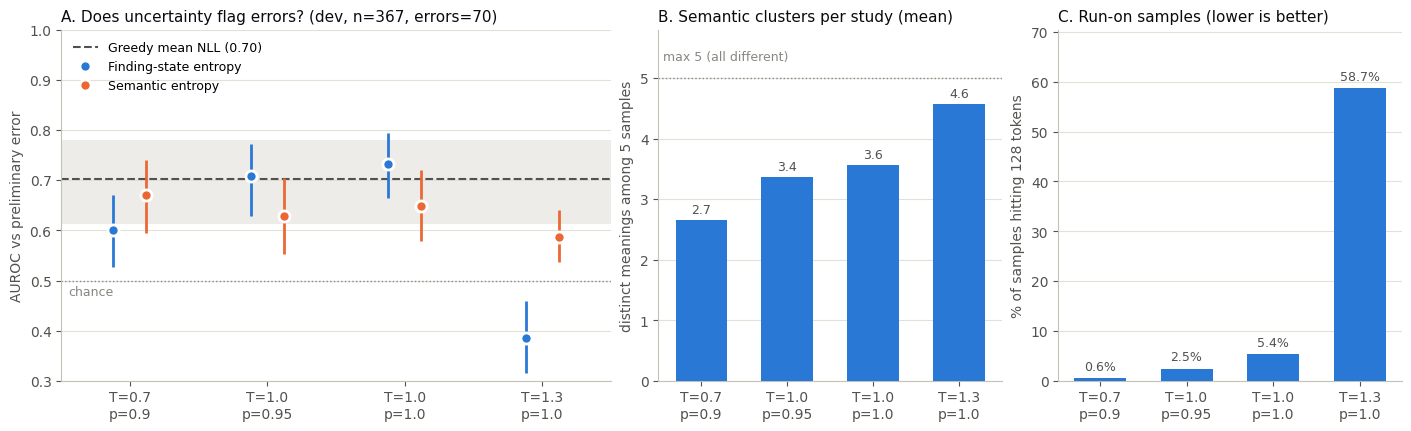

In [14]:
from sklearn.metrics import roc_auc_score
import numpy as np
import matplotlib.pyplot as plt

ref_labels = read_csv(OUT_DIR / "labels" / "labels_reference.csv")
greedy_labels = read_csv(OUT_DIR / "labels" / "labels_greedy.csv")

def preliminary_errors(split):
    usable = set(r[0] for r in eval_dataset(split).rows)
    ref = ref_labels[(ref_labels.split == split) & ref_labels.study_id.isin(usable)].set_index("study_id")[FINDINGS]
    gen = greedy_labels[(greedy_labels.split == split) & greedy_labels.study_id.isin(usable)].set_index("study_id")[FINDINGS]
    missing = usable - set(gen.index)
    assert not missing, f"{len(missing)} usable {split} studies have no greedy draft: rerun Step 8 and Step 10"
    ref, gen = ref.align(gen, join="inner", axis=0)
    unsupported = ((gen == "positive") & ref.isin(["negative", "unmentioned"])).any(axis=1)
    omission = ((ref == "positive") & gen.isin(["negative", "unmentioned"])).any(axis=1)
    return pd.DataFrame({"unsupported_prelim": unsupported, "omission_prelim": omission,
                         "any_error_prelim": unsupported | omission})

rng = np.random.default_rng(BASE_SEED)
def auroc_ci(y, score, reps=BOOTSTRAP_REPS):
    keep = score.notna()
    y, score = y[keep].to_numpy().astype(int), score[keep].to_numpy().astype(float)
    if len(set(y)) < 2:
        return float("nan"), float("nan"), float("nan")
    point = roc_auc_score(y, score)
    boots = []
    for _ in range(reps):
        idx = rng.integers(0, len(y), len(y))
        if len(set(y[idx])) == 2:
            boots.append(roc_auc_score(y[idx], score[idx]))
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return point, lo, hi

errors = preliminary_errors("dev")
nll = greedy_labels.set_index("study_id")["mean_nll"].replace("", "nan").astype(float).rename("mean_nll")
n_ref_pos = (ref_labels[ref_labels.study_id.isin(errors.index)][FINDINGS] == "positive").any(axis=1).sum()
print(f"Usable dev studies: {len(errors)} (excluded as generator-trained: {len(EXCLUDED_IDS & set(ref_labels[ref_labels.split=='dev'].study_id))})")
print(f"Reference reports with a positive selected finding: {n_ref_pos} | preliminary errors: {errors.any_error_prelim.sum()} "
      f"(unsupported {errors.unsupported_prelim.sum()}, omission {errors.omission_prelim.sum()})")
assert n_ref_pos > 0, "No positive findings in dev reference labels: reference texts are missing or wrong."
if errors.any_error_prelim.sum() < 10:
    print("⚠️ Fewer than 10 error cases: AUROCs below will be very noisy.")

rows = []
for tag in SAMPLING_GRID:
    u = read_csv(uncertainty_path("dev", tag)).set_index("study_id")
    for c in ["finding_state_entropy", "semantic_entropy", "mean_sample_tokens"]:
        u[c] = u[c].astype(float)
    m = u.join(errors, how="inner").join(nll)
    y = m.any_error_prelim
    fse = auroc_ci(y, m.finding_state_entropy)
    se = auroc_ci(y, m.semantic_entropy)
    nl = auroc_ci(y, m.mean_nll)
    rows.append({
        "sampling_tag": tag, "temperature": SAMPLING_GRID[tag][0], "top_p": SAMPLING_GRID[tag][1],
        "studies": len(m), "errors": int(y.sum()),
        "pct_all_5_identical": 100 * (m.n_unique_texts.astype(int) == 1).mean(),
        "mean_semantic_clusters": m.n_semantic_clusters.astype(int).mean(),
        "mean_FSE": m.finding_state_entropy.mean(), "mean_SE": m.semantic_entropy.mean(),
        "pct_SE_max": 100 * (m.semantic_entropy > 0.999).mean(),
        "pct_samples_hit_max_tokens": 100 * m.n_hit_max_new_tokens.astype(int).sum() / (NUM_SAMPLES * len(m)),
        "mean_sample_tokens": m.mean_sample_tokens.mean(),
        "AUROC_FSE": fse[0], "AUROC_FSE_lo": fse[1], "AUROC_FSE_hi": fse[2],
        "AUROC_SE": se[0], "AUROC_SE_lo": se[1], "AUROC_SE_hi": se[2],
        "AUROC_greedyNLL": nl[0], "AUROC_greedyNLL_lo": nl[1], "AUROC_greedyNLL_hi": nl[2],
    })
sens = pd.DataFrame(rows)
sens.to_csv(OUT_DIR / "validation" / "sensitivity_dev.csv", index=False)
errors.to_csv(OUT_DIR / "validation" / "preliminary_errors_dev.csv")
display(sens[["sampling_tag", "studies", "errors", "AUROC_FSE", "AUROC_FSE_lo", "AUROC_FSE_hi",
              "AUROC_SE", "AUROC_SE_lo", "AUROC_SE_hi", "AUROC_greedyNLL", "mean_semantic_clusters",
              "pct_SE_max", "pct_samples_hit_max_tokens"]].round(3))

# ---- figure: three panels, one measure each ----
BLUE, ORANGE = "#2a78d6", "#eb6834"                      # validated categorical slots 1-2
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({"font.family": "sans-serif", "font.size": 10, "axes.edgecolor": AXIS,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False})
x = np.arange(len(sens))
labels = [f"T={t}\np={p}" for t, p in zip(sens.temperature, sens.top_p)]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), layout="constrained",
                         gridspec_kw={"width_ratios": [1.6, 1, 1]})

ax = axes[0]
for off, col, name, key in [(-0.12, BLUE, "Finding-state entropy", "FSE"), (0.12, ORANGE, "Semantic entropy", "SE")]:
    yv = sens[f"AUROC_{key}"]
    err = [yv - sens[f"AUROC_{key}_lo"], sens[f"AUROC_{key}_hi"] - yv]
    ax.errorbar(x + off, yv, yerr=err, fmt="o", ms=8, color=col, ecolor=col, elinewidth=2, capsize=0,
                mec="white", mew=2, label=name, zorder=3)
g = sens.AUROC_greedyNLL.iloc[0]
ax.axhspan(sens.AUROC_greedyNLL_lo.iloc[0], sens.AUROC_greedyNLL_hi.iloc[0], color=GRID, alpha=0.6, lw=0, zorder=1)
ax.axhline(g, color=INK2, lw=1.5, ls="--", zorder=2, label=f"Greedy mean NLL ({g:.2f})")
ax.axhline(0.5, color=MUTED, lw=1, ls=":", zorder=2)
ax.text(-0.45, 0.49, "chance", color=MUTED, fontsize=9, ha="left", va="top")
ax.set_xticks(x, labels); ax.set_xlim(-0.5, len(sens) - 0.5); ax.set_ylim(0.3, 1.0)
ax.set_ylabel("AUROC vs preliminary error"); ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.set_title(f"A. Does uncertainty flag errors? (dev, n={int(sens.studies.iloc[0])}, errors={int(sens.errors.iloc[0])})",
             loc="left", color=INK, fontsize=11)
ax.legend(frameon=False, fontsize=9, loc="upper left")

ax = axes[1]
ax.bar(x, sens.mean_semantic_clusters, width=0.6, color=BLUE, zorder=3)
for xi, v in zip(x, sens.mean_semantic_clusters):
    ax.text(xi, v + 0.06, f"{v:.1f}", ha="center", va="bottom", color=INK2, fontsize=9)
ax.axhline(NUM_SAMPLES, color=MUTED, lw=1, ls=":"); ax.text(-0.45, NUM_SAMPLES + 0.3, f"max {NUM_SAMPLES} (all different)", color=MUTED, fontsize=9, ha="left")
ax.set_xlim(-0.5, len(sens) - 0.5)
ax.set_xticks(x, labels); ax.set_ylim(0, NUM_SAMPLES + 0.8); ax.set_ylabel("distinct meanings among 5 samples")
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.set_title("B. Semantic clusters per study (mean)", loc="left", color=INK, fontsize=11)

ax = axes[2]
ax.bar(x, sens.pct_samples_hit_max_tokens, width=0.6, color=BLUE, zorder=3)
for xi, v in zip(x, sens.pct_samples_hit_max_tokens):
    ax.text(xi, v + 1, f"{v:.1f}%", ha="center", va="bottom", color=INK2, fontsize=9)
ax.set_xticks(x, labels); ax.set_ylim(0, max(10, sens.pct_samples_hit_max_tokens.max() * 1.2))
ax.set_ylabel(f"% of samples hitting {MAX_NEW_TOKENS} tokens"); ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.set_title("C. Run-on samples (lower is better)", loc="left", color=INK, fontsize=11)

for ext in ("png", "svg"):
    fig.savefig(OUT_DIR / "validation" / f"sensitivity_dev.{ext}", dpi=200, facecolor="#fcfcfb")
plt.show()

## Step 13: Freeze ONE sampling setting (decide on dev only)
Look at the table and figure. A good setting has AUROCs at least as good as the others (overlapping intervals mean the difference isn't clear, so prefer the simpler/proposal default 0.7 / 0.9), few samples hitting the 128-token limit (panel C), not every study at the maximum number of meanings (panel B), and readable samples (Step 14).
Write the chosen tag below and run the cell. **Freeze it before looking at any test results.** The JSON is never overwritten with a different setting.

In [15]:
FROZEN_TAG = "t0.7_p0.90"   # frozen on dev: proposal setting, best semantic-entropy AUROC, fewest run-on samples
assert FROZEN_TAG in SAMPLING_GRID, "Set FROZEN_TAG to one of: " + ", ".join(SAMPLING_GRID)

frozen_file = OUT_DIR / "frozen_sampling_settings.json"
settings = {"sampling_tag": FROZEN_TAG, "temperature": SAMPLING_GRID[FROZEN_TAG][0],
            "top_p": SAMPLING_GRID[FROZEN_TAG][1], "top_k": 0, "num_samples": NUM_SAMPLES,
            "max_new_tokens": MAX_NEW_TOKENS, "base_seed": BASE_SEED,
            "findings": FINDINGS, "aggregation": AGGREGATION, "nli_model": NLI_MODEL,
            "chexbert": labeler.version, "checkpoint_id": CHECKPOINT_ID,
            "checkpoint_sha": CHECKPOINT_SHA, "generator_commit": GENERATOR_COMMIT,
            "split_source": ("official split CSVs: " + ", ".join(p.name for p in sources)) if OFFICIAL else "generator's own train/dev",
            "excluded_generator_training_studies": len(EXCLUDED_IDS),
            "selected_on": "dev"}
if frozen_file.exists():
    old = json.load(frozen_file.open())
    fixed = ["sampling_tag", "temperature", "top_p", "top_k", "num_samples", "max_new_tokens", "base_seed",
             "findings", "aggregation", "nli_model", "chexbert", "checkpoint_id", "checkpoint_sha", "generator_commit"]
    changed = {k: (old.get(k), settings[k]) for k in fixed if old.get(k) != settings[k]}
    assert not changed, f"Frozen settings differ from the current configuration: {changed}"
    print("Frozen settings unchanged ✅")
else:
    json.dump(settings, frozen_file.open("w"), indent=2)
print(json.dumps(settings, indent=2))

Frozen settings unchanged ✅
{
  "sampling_tag": "t0.7_p0.90",
  "temperature": 0.7,
  "top_p": 0.9,
  "top_k": 0,
  "num_samples": 5,
  "max_new_tokens": 128,
  "base_seed": 42,
  "findings": [
    "Atelectasis",
    "Cardiomegaly",
    "Consolidation",
    "Edema",
    "Pleural Effusion"
  ],
  "aggregation": "mean",
  "nli_model": "MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli",
  "chexbert": "CheXbert StanfordAIMI/RRG_scorers/chexbert.pth sha256:6550703c92d6",
  "checkpoint_id": "iu-baseline-100ep-seed42",
  "checkpoint_sha": "db2f4c237d4f-a3a2ee047d65",
  "generator_commit": "46e3d8c62ec18e9d3f943da07c80e0d157cb4a28",
  "split_source": "official split CSVs: dev.csv, prob_cal.csv, risk_cal.csv, test.csv, train.csv",
  "excluded_generator_training_studies": 0,
  "selected_on": "dev"
}


## Step 14: Inspect extraction and clustering failures (dev, frozen setting)
This saves `inspection_dev.csv` with an empty `reviewer_note` column. Read the rows and write short notes for the methods and results write-up.
- **Over-split (paraphrases)**: samples that seem to say the same thing ended up in different clusters.
- **Negation**: samples disagree positive vs negative on a finding. Check that CheXbert and the clustering handled "no effusion" vs "effusion" correctly.
- **Uncertain finding**: a sample hedges ("possible", "may represent"). Check how it was labeled and clustered.
- **Over-merged**: one cluster contains samples where CheXbert says *positive* for a selected finding and others where it doesn't.
- **CheXbert check**: reference reports CheXbert marks positive for a selected finding. Confirm by reading them.

In [16]:
pd.set_option("display.max_colwidth", 400)
ref_labels = read_csv(OUT_DIR / "labels" / "labels_reference.csv")
u = read_csv(uncertainty_path("dev", FROZEN_TAG)).set_index("study_id")
s = read_csv(samples_path("dev", FROZEN_TAG))
lab = read_csv(OUT_DIR / "labels" / f"labels_samples_dev_{FROZEN_TAG}.csv")
label_varies = lab.groupby("study_id")[FINDINGS].nunique().gt(1).any(axis=1)

n_clusters = u.n_semantic_clusters.astype(int)
over_split = n_clusters[n_clusters > 1].sort_values().index[:8]
# Over-merged: a cluster holding samples that disagree on positive vs not-positive for a selected finding
clusters = pd.DataFrame([(sid, str(k), c) for sid, a in u["cluster_assignment"].items()
                         for k, c in enumerate(a.split(","))], columns=["study_id", "sample_index", "cluster"])
cl = clusters.merge(lab.assign(sample_index=lab["sample_index"].astype(str)), on=["study_id", "sample_index"])
pos = cl[FINDINGS].eq("positive")
grp = pos.groupby([cl["study_id"], cl["cluster"]])
conflict = (grp.any() & ~grp.all()).any(axis=1)
conflict_studies = conflict[conflict].index.get_level_values("study_id").unique()
print(f"Studies with a cluster that mixes positive and not-positive samples: {len(conflict_studies)} of {len(u)} "
      f"({100 * len(conflict_studies) / len(u):.1f}%)")

over_merged = conflict_studies[:8]
# Proposal 4.3: review examples with negation (positive vs negative across samples) and uncertain findings
states_by_study = lab.groupby("study_id")[FINDINGS].agg(lambda x: set(x))
negation = states_by_study[states_by_study.apply(lambda r: any({"positive", "negative"} <= v for v in r), axis=1)].index[:8]
uncertain = states_by_study[states_by_study.apply(lambda r: any("uncertain" in v for v in r), axis=1)].index[:8]
chex_pos = ref_labels[(ref_labels.split == "dev") & ref_labels.study_id.isin(u.index)
                      & (ref_labels[FINDINGS] == "positive").any(axis=1)].study_id[:8]

rows = []
for kind, ids in [("over_split? (paraphrase)", over_split), ("over_merged?", over_merged),
                  ("negation", negation), ("uncertain_finding", uncertain)]:
    for sid in ids:
        g = s[s.study_id == sid].sort_values("sample_index")
        assign = u.loc[sid, "cluster_assignment"].split(",")
        for (_, r), cid in zip(g.iterrows(), assign):
            l = lab[(lab.study_id == sid) & (lab.sample_index == r.sample_index)].iloc[0]
            rows.append({"check": kind, "study_id": sid, "sample_index": r.sample_index, "cluster": cid,
                         "text": r.generated_text, **{f: l[f] for f in FINDINGS}, "reviewer_note": ""})
for sid in chex_pos:
    r = ref_labels[ref_labels.study_id == sid].iloc[0]
    rows.append({"check": "chexbert_reference_positive", "study_id": sid, "sample_index": "", "cluster": "",
                 "text": manifest.set_index("study_id").loc[sid, "reference_text"],
                 **{f: r[f] for f in FINDINGS}, "reviewer_note": ""})
inspection = pd.DataFrame(rows)
inspection.to_csv(OUT_DIR / "validation" / "inspection_dev.csv", index=False)
print(f"over-split: {len(over_split)} | over-merged: {len(over_merged)} | negation: {len(negation)} | "
      f"uncertain: {len(uncertain)} | reference positives: {len(chex_pos)}")
display(inspection.head(40))

Studies with a cluster that mixes positive and not-positive samples: 23 of 367 (6.3%)
over-split: 8 | over-merged: 8 | negation: 8 | uncertain: 2 | reference positives: 8


,check,study_id,sample_index,cluster,text,Atelectasis,Cardiomegaly,Consolidation,Edema,Pleural Effusion,reviewer_note
0,over_split? (paraphrase),CXR983,0,0,Findings: Heart size is normal. Lungs are clear. There is no focal airspace consolidation. No pleural effusion or pneumothorax. Impression: No acute cardiopulmonary process.,unmentioned,negative,negative,unmentioned,negative,
1,over_split? (paraphrase),CXR983,1,0,"Findings: The cardiomediastinal silhouette and pulmonary vasculature are within normal limits in size. The lungs are clear of focal airspace disease, pneumothorax, or pleural effusion. There is no acute bony abnormality. Impression: No acute cardiopulmonary process.",unmentioned,unmentioned,unmentioned,unmentioned,negative,
2,over_split? (paraphrase),CXR983,2,1,"Findings: The heart size and cardiomediastinal silhouette are within normal limits for size and contour. There is no focal airspace consolidation, pleural effusion, or pneumothorax. There is no acute bony abnormality. Impression: No acute cardiopulmonary abnormality.",unmentioned,negative,negative,unmentioned,negative,
3,over_split? (paraphrase),CXR983,3,1,Findings: The heart is normal in size and contour. The mediastinum is unremarkable. The lungs are clear. Impression: No acute disease.,unmentioned,negative,unmentioned,unmentioned,unmentioned,
4,over_split? (paraphrase),CXR983,4,1,"Findings: Heart size is normal. The mediastinal contour is within normal limits. There is no focal consolidation, pneumothorax, or large pleural effusion. The visualized bony structures reveal no acute bony abnormalities. Impression: No acute cardiopulmonary abnormalities.",unmentioned,negative,negative,unmentioned,negative,
5,over_split? (paraphrase),CXR975,0,0,Findings: The heart is normal in size. The mediastinum is unremarkable. The lungs are clear. Impression: No acute disease.,unmentioned,negative,unmentioned,unmentioned,unmentioned,
6,over_split? (paraphrase),CXR975,1,0,Findings: Cardiac and mediastinal contours are within normal limits. The lungs are clear. Bony structures are intact. Impression: No acute findings.,unmentioned,negative,unmentioned,unmentioned,unmentioned,
7,over_split? (paraphrase),CXR975,2,1,"Findings: The lungs are clear bilaterally. Specifically, no evidence of focal consolidation, pneumothorax, or pleural effusion.. Cardiomediastinal silhouette is unremarkable. Visualized osseous structures of the thorax are without acute abnormality. Impression: No acute cardiopulmonary abnormality..",unmentioned,unmentioned,negative,unmentioned,negative,
8,over_split? (paraphrase),CXR975,3,0,"Findings: There is a calcified granuloma in the left upper lobe. No pleural effusion or pneumothorax. Heart size is within normal limits. There is no focal air space opacity, pleural effusion or pneumothorax. Impression: 1. No acute cardiopulmonary abnormality.",unmentioned,negative,unmentioned,unmentioned,negative,
9,over_split? (paraphrase),CXR975,4,1,Findings: The lungs are clear. There is no focal airspace disease. The heart is normal in size and contour. The pulmonary vascularity is normal. The lungs are clear. Impression: No acute pulmonary disease.,unmentioned,negative,unmentioned,unmentioned,unmentioned,


## Step 15: Final splits with the frozen setting (test and risk_cal)
Run only after Step 13. For each split in `FINAL_SPLITS`, this generates any missing greedy drafts, samples with the frozen setting, labels everything and builds the uncertainty file. risk_cal is included because Person 4's risk-control calibration needs S on it. Studies the generator was trained on are left out (see Step 5's table).

In [17]:
frozen_file = OUT_DIR / "frozen_sampling_settings.json"
if not frozen_file.exists():
    print("First freeze a sampling setting in Step 13 (on dev).")
else:
    frozen = json.load(frozen_file.open())
    FROZEN_TAG = frozen["sampling_tag"]
    for k, v in {"num_samples": NUM_SAMPLES, "max_new_tokens": MAX_NEW_TOKENS, "base_seed": BASE_SEED}.items():
        assert frozen[k] == v, f"{k}: frozen {frozen[k]} but the current setting is {v}"
    todo = [sp for sp in FINAL_SPLITS if sp in SPLITS]
    if not todo:
        print("No test / risk_cal split yet: put the official split CSVs in", SPLITS_DIR)
    for split in todo:
        ensure_greedy(split)
        sample_split(split, FROZEN_TAG, frozen["temperature"], frozen["top_p"])
    if todo:
        label_everything()
        for split in todo:
            u = build_uncertainty(split, FROZEN_TAG)
            print(f"\n{split}: {len(u)} studies")
            print(u[["finding_state_entropy", "semantic_entropy"]].describe().round(3))

test: 550 usable studies, 550 already have a greedy draft, generating 0


greedy test: 0it [00:00, ?it/s]

test t0.7_p0.90:   0%|          | 0/550 [00:00<?, ?it/s]

Saved /content/drive/MyDrive/CXR-Sentry/person3_outputs/samples/samples_test_t0.7_p0.90.csv
risk_cal: 367 usable studies, 367 already have a greedy draft, generating 0


greedy risk_cal: 0it [00:00, ?it/s]

risk_cal t0.7_p0.90:   0%|          | 0/367 [00:00<?, ?it/s]

... (17 outputs left out)

NLI:   0%|          | 0/224 [00:00<?, ?it/s]


test: 550 studies
       finding_state_entropy  semantic_entropy
count                550.000           550.000
mean                   0.210             0.512
std                    0.077             0.235
min                    0.000             0.000
25%                    0.169             0.311
50%                    0.217             0.590
75%                    0.266             0.655
max                    0.491             1.000


NLI:   0%|          | 0/143 [00:00<?, ?it/s]


risk_cal: 367 studies
       finding_state_entropy  semantic_entropy
count                367.000           367.000
mean                   0.215             0.521
std                    0.078             0.233
min                    0.000             0.000
25%                    0.169             0.311
50%                    0.224             0.590
75%                    0.266             0.655
max                    0.394             1.000


## Step 16: Handoff
This copies the files each person needs into `person3_outputs/handoff_*` folders. Share those folders on Drive.
Every file includes `study_id`, `split`, the checkpoint or labeler version, and CheXbert's standard finding names.

In [18]:
frozen = json.load((OUT_DIR / "frozen_sampling_settings.json").open())
tag = frozen["sampling_tag"]
to_p2 = OUT_DIR / "handoff_person2"
to_p4 = OUT_DIR / "handoff_person4"
for d in (to_p2, to_p4):
    d.mkdir(exist_ok=True)

shared = [OUT_DIR / "labels" / "labels_reference.csv", OUT_DIR / "labels" / "labels_greedy.csv",
          OUT_DIR / "frozen_sampling_settings.json"]
for p in shared:
    shutil.copy(p, to_p2); shutil.copy(p, to_p4)
for split in ("dev", "test", "risk_cal"):
    for p in [uncertainty_path(split, tag), samples_path(split, tag),
              OUT_DIR / "labels" / f"labels_samples_{split}_{tag}.csv"]:
        if p.exists():
            shutil.copy(p, to_p4)
for p in list((OUT_DIR / "validation").glob("sensitivity_dev.*")) + [OUT_DIR / "validation" / "generator_overlap.csv"]:
    shutil.copy(p, to_p4)
shutil.copy(OUT_DIR / "validation" / "generator_overlap.csv", to_p2)

# Required format (Participant3_README.md): one file per split, five findings,
# values positive / negative / uncertain / not_mentioned (CheXbert "unmentioned" -> "not_mentioned")
chex_dir = OUT_DIR / "chexbert_labels"
chex_dir.mkdir(exist_ok=True)
ref_all = read_csv(OUT_DIR / "labels" / "labels_reference.csv")
image_id = {r.study_id: Path(r.image_path.replace("\\", "/")).stem for r in manifest.itertuples()}
COLS = {"Atelectasis": "atelectasis", "Cardiomegaly": "cardiomegaly", "Pleural Effusion": "pleural_effusion",
        "Consolidation": "consolidation", "Edema": "edema"}
for split, g in ref_all.groupby("split"):
    out = pd.DataFrame({"study_id": g.study_id, "image_id": g.study_id.map(image_id)})
    for src, dst in COLS.items():
        out[dst] = g[src].replace({"unmentioned": "not_mentioned"})
    out.to_csv(chex_dir / f"{split}_chexbert_labels.csv", index=False)
shutil.copy(chex_dir / "prob_cal_chexbert_labels.csv", to_p2 / "prob_cal_chexbert_labels.csv")
pc = read_csv(to_p2 / "prob_cal_chexbert_labels.csv")
print("prob_cal_chexbert_labels.csv:", len(pc), "studies | values:", sorted(set(pc[list(COLS.values())].values.ravel())))
print("Label mapping: CheXbert positive→positive, negative→negative, uncertain→uncertain, blank/unmentioned→not_mentioned")

for d in (to_p2, to_p4):
    print(d.name, "→", sorted(x.name for x in d.iterdir()))

prob_cal_chexbert_labels.csv: 367 studies | values: ['negative', 'not_mentioned', 'positive', 'uncertain']
Label mapping: CheXbert positive→positive, negative→negative, uncertain→uncertain, blank/unmentioned→not_mentioned
handoff_person2 → ['README_labels.txt', 'calibration_support_prob_cal.csv', 'frozen_sampling_settings.json', 'generator_overlap.csv', 'labels_greedy.csv', 'labels_reference.csv', 'prob_cal_chexbert_labels.csv']
handoff_person4 → ['README_labels.txt', 'frozen_sampling_settings.json', 'generator_overlap.csv', 'labels_greedy.csv', 'labels_reference.csv', 'labels_samples_dev_t0.7_p0.90.csv', 'labels_samples_risk_cal_t0.7_p0.90.csv', 'labels_samples_test_t0.7_p0.90.csv', 'samples_dev_t0.7_p0.90.csv', 'samples_risk_cal_t0.7_p0.90.csv', 'samples_test_t0.7_p0.90.csv', 'sensitivity_dev.csv', 'sensitivity_dev.png', 'sensitivity_dev.svg', 'uncertainty_dev_t0.7_p0.90.csv', 'uncertainty_risk_cal_t0.7_p0.90.csv', 'uncertainty_test_t0.7_p0.90.csv']


In [19]:
# ===== Step 17: handoff cleanup + verification (standalone: no GPU, no models, no rerun) =====
from google.colab import drive
drive.mount("/content/drive")

import json, shutil
import pandas as pd
from pathlib import Path

DRIVE_ROOT = Path("/content/drive/MyDrive/CXR-Sentry")
SPLITS_DIR = DRIVE_ROOT / "handoff" / "splits"
OUT = DRIVE_ROOT / "person3_outputs"
TO_P2, TO_P4 = OUT / "handoff_person2", OUT / "handoff_person4"
read = lambda p: pd.read_csv(p, dtype=str, keep_default_na=False)
CONDITIONS = ["Enlarged Cardiomediastinum", "Cardiomegaly", "Lung Opacity", "Lung Lesion", "Edema",
              "Consolidation", "Pneumonia", "Atelectasis", "Pneumothorax", "Pleural Effusion",
              "Pleural Other", "Fracture", "Support Devices", "No Finding"]
FINDINGS = ["Atelectasis", "Cardiomegaly", "Consolidation", "Edema", "Pleural Effusion"]
STATES = {"positive", "negative", "uncertain", "not_mentioned"}

frozen = json.load((OUT / "frozen_sampling_settings.json").open())
TAG = frozen["sampling_tag"]
splits = pd.concat([read(p).assign(split=p.stem) for p in sorted(SPLITS_DIR.glob("*.csv"))], ignore_index=True)
image_id = splits.set_index("study_id")["image_id"]
expected = splits.groupby("split")["study_id"].apply(set).to_dict()
problems = []

def clean(df, name):
    # add image_id next to study_id and use not_mentioned (Participant 2's vocabulary) in every label column
    df = df.copy()
    if "image_id" not in df.columns:
        df.insert(1, "image_id", df["study_id"].map(image_id))
    for c in [c for c in CONDITIONS if c in df.columns]:
        df[c] = df[c].replace({"unmentioned": "not_mentioned"})
        bad = set(df[c]) - STATES
        if bad: problems.append(f"{name}: unexpected values {bad} in {c}")
    if df["image_id"].isna().any() or df["image_id"].eq("").any():
        problems.append(f"{name}: {int(df['image_id'].isna().sum())} rows without image_id")
    return df

# 1) Reference + greedy label files (the copies in labels/ stay unchanged; the notebook reads those)
ref = clean(read(OUT / "labels" / "labels_reference.csv"), "labels_reference")
gre = clean(read(OUT / "labels" / "labels_greedy.csv"), "labels_greedy")
for d in (TO_P2, TO_P4):
    ref.to_csv(d / "labels_reference.csv", index=False)
    gre.to_csv(d / "labels_greedy.csv", index=False)

# 2) Sample label files for the frozen setting
for split in ("dev", "test", "risk_cal"):
    p = OUT / "labels" / f"labels_samples_{split}_{TAG}.csv"
    if p.exists():
        clean(read(p), p.name).to_csv(TO_P4 / p.name, index=False)

# 3) Remove obsolete files from the handoff folders (other sampling settings, old manifests)
for d in (TO_P2, TO_P4):
    for p in d.iterdir():
        stale = ("_t" in p.stem and TAG not in p.stem and not p.stem.startswith("sensitivity")) or "manifest_full" in p.name
        if stale:
            p.unlink(); print("removed obsolete", d.name, "/", p.name)

# 4) Calibration support: explicit positive/negative counts per finding in prob_cal
pc = ref[ref.split == "prob_cal"]
support = pd.DataFrame({f: pc[f].value_counts() for f in FINDINGS}).reindex(
    ["positive", "negative", "uncertain", "not_mentioned"]).fillna(0).astype(int).T
support["explicit_total"] = support["positive"] + support["negative"]
support["enough_for_calibration"] = (support["positive"] >= 10) & (support["negative"] >= 10)
support.to_csv(OUT / "validation" / "calibration_support_prob_cal.csv")
shutil.copy(OUT / "validation" / "calibration_support_prob_cal.csv", TO_P2)
print("Explicit labels in prob_cal (rule of thumb: >= 10 of each to calibrate):")
print(support)

# 5) Rename "under_merged?" to "over_merged?" in the inspection file (keeps your reviewer notes)
insp = OUT / "validation" / "inspection_dev.csv"
if insp.exists():
    i = read(insp); i["check"] = i["check"].replace({"under_merged?": "over_merged?"}); i.to_csv(insp, index=False)

# 6) Verify study membership, duplicates and missing labels
def check(df, name, split, need_all=True):
    sub = df[df.split == split]
    if sub.study_id.duplicated().any(): problems.append(f"{name}/{split}: duplicate study_id")
    missing = expected[split] - set(sub.study_id)
    extra = set(sub.study_id) - expected[split]
    if need_all and missing: problems.append(f"{name}/{split}: {len(missing)} studies missing")
    if extra: problems.append(f"{name}/{split}: {len(extra)} studies not in the official split")
    if sub[FINDINGS].eq("").any().any(): problems.append(f"{name}/{split}: empty labels")
for split in expected:
    check(ref, "labels_reference", split)
for split in ("dev", "test", "risk_cal"):
    check(gre, "labels_greedy", split)
    u = OUT / "uncertainty" / f"uncertainty_{split}_{TAG}.csv"
    if u.exists():
        uu = read(u)
        if set(uu.study_id) != expected[split]: problems.append(f"{u.name}: study set differs from the official split")
        if uu.study_id.duplicated().any(): problems.append(f"{u.name}: duplicate study_id")
    s = OUT / "samples" / f"samples_{split}_{TAG}.csv"
    if s.exists():
        ss = read(s)
        per = ss.groupby("study_id")["sample_index"].apply(lambda x: sorted(x.astype(int)))
        if not per.apply(lambda x: x == list(range(frozen["num_samples"]))).all():
            problems.append(f"{s.name}: some studies don't have exactly sample_index 0..{frozen['num_samples'] - 1}")
        for col, key in (("temperature", "temperature"), ("top_p", "top_p"), ("max_new_tokens", "max_new_tokens")):
            if not ss[col].astype(float).eq(float(frozen[key])).all():
                problems.append(f"{s.name}: {col} differs from the frozen setting")

(TO_P2 / "README_labels.txt").write_text(
    "CheXbert labels (StanfordAIMI/RRG_scorers chexbert.pth). Values: positive, negative, uncertain, not_mentioned.\n"
    "Mapping from CheXbert: positive->positive, negative->negative, uncertain->uncertain, blank->not_mentioned.\n"
    "Uncertain and not_mentioned are NOT negative. Splits: official split CSVs. Generator-trained studies outside train: 0.\n"
    f"Frozen sampling setting: {TAG}.\n")
shutil.copy(TO_P2 / "README_labels.txt", TO_P4)

print("\nCHECKS:", "all passed ✅" if not problems else "")
for p in problems: print(" ❌", p)
for d in (TO_P2, TO_P4):
    print(d.name, "→", sorted(x.name for x in d.iterdir()))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Explicit labels in prob_cal (rule of thumb: >= 10 of each to calibrate):
                  positive  negative  uncertain  not_mentioned  \
Atelectasis             24         2         12            329   
Cardiomegaly            40       247         10             70   
Consolidation            5       105          0            257   
Edema                    7        36          4            320   
Pleural Effusion        11       252          2            102   

                  explicit_total  enough_for_calibration  
Atelectasis                   26                   False  
Cardiomegaly                 287                    True  
Consolidation                110                   False  
Edema                         43                   False  
Pleural Effusion             263                    True  

CHECKS: all passed ✅
handoff_person2 → ['READM

In [21]:
# ===== Step 18: automatic review of clustering and extraction (standalone: no GPU, no rerun) =====
from google.colab import drive
drive.mount("/content/drive")

import json, re
import pandas as pd
from pathlib import Path

OUT = Path("/content/drive/MyDrive/CXR-Sentry/person3_outputs")
read = lambda p: pd.read_csv(p, dtype=str, keep_default_na=False)
FINDINGS = ["Atelectasis", "Cardiomegaly", "Consolidation", "Edema", "Pleural Effusion"]
TAG = json.load((OUT / "frozen_sampling_settings.json").open())["sampling_tag"]

u = read(OUT / "uncertainty" / f"uncertainty_dev_{TAG}.csv").set_index("study_id")
lab = read(OUT / "labels" / f"labels_samples_dev_{TAG}.csv")
lab["sample_index"] = lab["sample_index"].astype(int)
smp = read(OUT / "samples" / f"samples_dev_{TAG}.csv")
smp["sample_index"] = smp["sample_index"].astype(int)
ref = read(OUT / "labels" / "labels_reference.csv").set_index("study_id")
text_of = read(Path("/content/drive/MyDrive/CXR-Sentry/handoff/splits/dev.csv")).set_index("study_id")["target_text"]

# one row per sample with its cluster
rows = [(sid, k, int(c)) for sid, a in u["cluster_assignment"].items() for k, c in enumerate(a.split(","))]
cl = pd.DataFrame(rows, columns=["study_id", "sample_index", "cluster"]).merge(
    lab[["study_id", "sample_index"] + FINDINGS], on=["study_id", "sample_index"]).merge(
    smp[["study_id", "sample_index", "generated_text"]], on=["study_id", "sample_index"])
cl["sig"] = cl[FINDINGS].eq("positive").astype(int).astype(str).agg("".join, axis=1)   # positive vs not-positive per finding

# --- study-level classification over ALL dev studies ---
NEG = re.compile(r"\b(no|without|negative for|free of|clear of|resolved)\b[^.]{0,60}$", re.I)
WORDS = {"Atelectasis": "atelecta", "Cardiomegaly": "cardiomegal|heart (size )?is (mildly |moderately )?enlarged|enlarged heart",
         "Consolidation": "consolidat", "Edema": "edema", "Pleural Effusion": "effusion"}
def mention_negated(text, finding):
    # True if every mention of the finding is preceded (same sentence) by a negation word
    hits = [m.start() for m in re.finditer(WORDS[finding], text, re.I)]
    return bool(hits) and all(NEG.search(text[max(0, text.rfind(".", 0, h) + 1):h]) for h in hits)

study_rows, notes = [], {}
for sid, g in cl.groupby("study_id"):
    n_cl = g["cluster"].nunique()
    split_same_labels = n_cl > 1 and g.groupby("cluster")["sig"].agg(set).apply(frozenset).nunique() == 1 \
        and g["sig"].nunique() == 1
    conflicts = []
    for c, gc in g.groupby("cluster"):
        for f in FINDINGS:
            pos = gc[gc[f] == "positive"]
            if len(pos) and len(pos) < len(gc):
                # extraction error if the "positive" sample's text actually negates the finding
                kind = "extraction" if all(mention_negated(t, f) for t in pos["generated_text"]) else "clustering"
                conflicts.append((c, f, kind))
    study_rows.append({"study_id": sid, "n_clusters": n_cl,
                       "over_split_paraphrase": split_same_labels,
                       "over_merged": bool(conflicts),
                       "over_merged_clustering": any(k == "clustering" for *_, k in conflicts),
                       "over_merged_extraction": any(k == "extraction" for *_, k in conflicts)})
    notes[sid] = conflicts
review = pd.DataFrame(study_rows).set_index("study_id")
review.to_csv(OUT / "validation" / "auto_review_dev.csv")

n = len(review)
multi = (review.n_clusters > 1).sum()
summary = {
    "dev_studies": n,
    "studies_with_more_than_one_cluster": int(multi),
    "over_split_same_finding_labels": int(review.over_split_paraphrase.sum()),
    "over_split_share_of_multi_cluster_studies_pct": round(100 * review.over_split_paraphrase.sum() / max(multi, 1), 1),
    "over_merged_studies": int(review.over_merged.sum()),
    "over_merged_pct": round(100 * review.over_merged.mean(), 1),
    "over_merged_likely_clustering_error": int(review.over_merged_clustering.sum()),
    "over_merged_likely_extraction_error": int(review.over_merged_extraction.sum()),
}

# --- CheXbert check on dev reference reports: does a "positive" label contradict an explicit negation? ---
chex = []
for sid in u.index:
    t = text_of.get(sid, "")
    for f in FINDINGS:
        if ref.loc[sid, f] == "positive":
            chex.append({"study_id": sid, "finding": f, "negated_in_text": mention_negated(t, f)})
chex = pd.DataFrame(chex)
summary["reference_positive_labels_checked"] = len(chex)
summary["reference_positive_labels_contradicted_by_negation"] = int(chex["negated_in_text"].sum()) if len(chex) else 0
json.dump(summary, (OUT / "validation" / "auto_review_summary.json").open("w"), indent=2)

# --- fill reviewer_note in inspection_dev.csv ---
insp_path = OUT / "validation" / "inspection_dev.csv"
insp = read(insp_path)
def note(r):
    sid, chk = r["study_id"], r["check"]
    if sid not in review.index and not chk.startswith("chexbert"):
        return ""
    if chk.startswith("over_split"):
        return ("AUTO: all samples agree on which findings are positive -> paraphrase over-split (same clinical meaning, split by NLI)"
                if review.loc[sid, "over_split_paraphrase"] else
                "AUTO: samples disagree on which findings are positive -> split reflects a real clinical difference")
    if chk.startswith("over_merged"):
        c = notes.get(sid, [])
        return "AUTO: " + "; ".join(f"cluster {k} mixes positive/not-positive {f} ({kind} error likely)" for k, f, kind in c) if c else ""
    if chk == "negation":
        return "AUTO: samples disagree positive vs negative on a finding; " + (
            "they are in different clusters (handled correctly)" if review.loc[sid, "n_clusters"] > 1 else "they share one cluster (over-merged)")
    if chk == "uncertain_finding":
        return "AUTO: hedged finding ('possible'/'may'); CheXbert labelled it uncertain, kept separate from positive/negative"
    if chk.startswith("chexbert"):
        f_pos = [f for f in FINDINGS if r[f] == "positive"]
        bad = [f for f in f_pos if mention_negated(r["text"], f)]
        return ("AUTO: positive label for " + ", ".join(bad) + " contradicts an explicit negation in the text (possible CheXbert error)"
                if bad else "AUTO: positive label(s) " + ", ".join(f_pos) + " consistent with the report text")
    return ""
insp["reviewer_note"] = [note(r) if (not r["reviewer_note"].strip() or r["reviewer_note"].startswith("AUTO:")) else r["reviewer_note"]
                         for _, r in insp.iterrows()]   # keeps notes you wrote yourself, refreshes AUTO notes
insp.to_csv(insp_path, index=False)
for d in ("handoff_person4",):
    for f in ("auto_review_dev.csv", "auto_review_summary.json", "inspection_dev.csv"):
        src = OUT / "validation" / f
        (OUT / d / f).write_bytes(src.read_bytes())

print(json.dumps(summary, indent=2))
print(f"\nFilled reviewer_note for {(insp.reviewer_note != '').sum()} of {len(insp)} rows in inspection_dev.csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{
  "dev_studies": 367,
  "studies_with_more_than_one_cluster": 346,
  "over_split_same_finding_labels": 273,
  "over_split_share_of_multi_cluster_studies_pct": 78.9,
  "over_merged_studies": 23,
  "over_merged_pct": 6.3,
  "over_merged_likely_clustering_error": 23,
  "over_merged_likely_extraction_error": 0,
  "reference_positive_labels_checked": 91,
  "reference_positive_labels_contradicted_by_negation": 0
}

Filled reviewer_note for 138 of 138 rows in inspection_dev.csv
